# w1 · EDA · 48 features · Manual segment (KKBox churn)

Exploratory analysis of the 48 features used in `w1_manual_data_reweighting`.
Focus: **which features separate churners from non-churners?**

## Sections
1. Dataset overview — shape, dtypes, missing values
2. Target variable — churn distribution, plan-segment breakdown
3. Categorical features — churn rate per category
4. Numerical features — boxplots: no-churn vs churn
5. Spearman correlation with churn — ranked discriminative power
6. XGBoost feature importance — from trained `XGB_reweight` model
7. Feature drift — standardised mean shift Feb → Mar

## 0. Setup

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import joblib
from scipy.stats import spearmanr
from datetime import date
from pathlib import Path
warnings.filterwarnings('ignore')

HERE = Path.cwd().resolve()
ROOT = None
for _p in [HERE, *HERE.parents]:
    if (_p / 'eda' / '_common.py').exists():
        ROOT = _p
        sys.path.insert(0, str(_p / 'eda'))
        break
if ROOT is None:
    raise FileNotFoundError('Cannot find workshops/eda/_common.py')
import _common as C

W1_DIR        = ROOT / 'w1' / 'export-tabular-v5'
ARTIFACTS_DIR = ROOT / 'w1' / 'artifacts' / 'sherlock_w1_manual_reweighting'

FEB_CUTOFF = date(2017, 1, 31)
MAR_CUTOFF = date(2017, 2, 28)
PLAN_THR   = 31

print(f'ROOT:         {ROOT}')
print(f'ARTIFACTS:    {ARTIFACTS_DIR}')

ROOT:         C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops
ARTIFACTS:    C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\artifacts\sherlock_w1_manual_reweighting


## 1. Feature configuration

In [2]:
CAT = ['city', 'registered_via', 'last_payment_method_id']

_NUM_59 = [
    'bd', 'bd_missing', 'tenure_days', 'registration_year', 'registration_month',
    'has_member_record', 'is_cancel_change_flag', 'is_auto_renew_change_flag',
    'transaction_count', 'average_amount_paid', 'average_amount_charged',
    'average_plan', 'n_payment_methods', 'n_plans', 'n_list_prices', 'n_amounts_paid',
    'duration', 'plan_coverage_ratio', 'sum_plan_days', 'sum_list_price',
    'sum_amount_paid', 'more_than_30', 'autorenew_not_cancel', 'not_autorenew_cancel',
    'max_plan_days', 'last_plan_days', 'last_is_auto_renew', 'last_is_cancel',
    'last_discount', 'days_to_expire', 'expire_dayofweek', 'days_since_last_transaction',
    'difference', 'has_transactions',
    'sum_last_month_unq', 'sum_last_month_total_secs', 'mean_last_month_total_secs',
    'last_login', 'last_sum_total_songs', 'last_ratio_100', 'last_ratio_25',
    'sum_last_second_month_total_secs', 'last_second_login',
    'last_second_sum_total_songs', 'last_second_ratio_100', 'last_second_ratio_25',
    'last_third_sum_total_songs', 'last_third_ratio_100', 'last_third_ratio_25',
    'login_difference', 'trend_songs', 'trend_secs', 'trend_ratio100', 'trend_ratio25',
    'days_since_last_log', 'has_listening_logs',
]
_DROP = {
    'has_transactions', 'last_is_cancel', 'autorenew_not_cancel', 'not_autorenew_cancel',
    'last_is_auto_renew', 'is_auto_renew_change_flag', 'is_cancel_change_flag',
    'last_discount', 'bd_missing', 'expire_dayofweek', 'n_amounts_paid',
}
NUM      = [f for f in _NUM_59 if f not in _DROP]
FEATURES = CAT + NUM

GROUPS = {
    'Member & Registration': [
        'bd', 'tenure_days', 'registration_year', 'registration_month', 'has_member_record',
    ],
    'Transaction volume': [
        'transaction_count', 'average_amount_paid', 'average_amount_charged',
        'average_plan', 'n_payment_methods', 'n_plans', 'n_list_prices',
    ],
    'Plan & timing': [
        'duration', 'plan_coverage_ratio', 'sum_plan_days', 'sum_list_price',
        'sum_amount_paid', 'more_than_30', 'max_plan_days', 'last_plan_days',
        'days_to_expire', 'days_since_last_transaction', 'difference',
    ],
    'Listening — last month': [
        'sum_last_month_unq', 'sum_last_month_total_secs', 'mean_last_month_total_secs',
        'last_login', 'last_sum_total_songs', 'last_ratio_100', 'last_ratio_25',
    ],
    'Listening — 2nd & 3rd month': [
        'sum_last_second_month_total_secs', 'last_second_login',
        'last_second_sum_total_songs', 'last_second_ratio_100', 'last_second_ratio_25',
        'last_third_sum_total_songs', 'last_third_ratio_100', 'last_third_ratio_25',
    ],
    'Trends & activity': [
        'login_difference', 'trend_songs', 'trend_secs',
        'trend_ratio100', 'trend_ratio25', 'days_since_last_log', 'has_listening_logs',
    ],
}

print(f'{len(CAT)} categorical + {len(NUM)} numerical = {len(FEATURES)} features total')
print(f'Dropped from original 59: {sorted(_DROP)}')

3 categorical + 45 numerical = 48 features total
Dropped from original 59: ['autorenew_not_cancel', 'bd_missing', 'expire_dayofweek', 'has_transactions', 'is_auto_renew_change_flag', 'is_cancel_change_flag', 'last_discount', 'last_is_auto_renew', 'last_is_cancel', 'n_amounts_paid', 'not_autorenew_cancel']


## 2. Data loading

In [3]:
# February
C.set_cutoff(FEB_CUTOFF)
cohort     = C.load_cohort()
_users_feb = cohort.select('msno', 'is_churn')
txn_feb    = C.clean_transactions(_users_feb)
state_feb  = C.subscription_state(txn_feb, _users_feb)

state_map_feb = dict(zip(state_feb['msno'].to_list(), state_feb['state'].to_list()))
split_map     = dict(zip(cohort['msno'].to_list(), cohort['split'].to_list()))

feb_raw          = pd.read_parquet(W1_DIR / 'train_feb.parquet')
feb_raw['state'] = feb_raw['msno'].map(state_map_feb)
feb_raw['split'] = feb_raw['msno'].map(split_map)
feb_m            = feb_raw[feb_raw['state'] == 'manual'].copy()

plan_map_feb = dict(zip(state_feb['msno'].to_list(), state_feb['last_plan_days'].to_list()))
feb_m['plan_seg'] = (
    feb_m['msno'].map(plan_map_feb).fillna(0).gt(PLAN_THR)
    .map({True: '>31d', False: '<=31d'})
)

# March
C.set_cutoff(MAR_CUTOFF)
mar_users     = pl.read_parquet(C.PARQUET_DIR / 'train_v2.parquet', columns=['msno', 'is_churn'])
txn_mar       = C.clean_transactions(mar_users)
state_mar     = C.subscription_state(txn_mar, mar_users)
state_map_mar = dict(zip(state_mar['msno'].to_list(), state_mar['state'].to_list()))

mar_raw          = pd.read_parquet(W1_DIR / 'test.parquet')
mar_raw['state'] = mar_raw['msno'].map(state_map_mar)
mar_m            = mar_raw[mar_raw['state'] == 'manual'].copy()

C.set_cutoff(FEB_CUTOFF)

print(f'Feb manual: {len(feb_m):,} | churn: {feb_m["is_churn"].mean():.2%}')
print(f'Mar manual: {len(mar_m):,} | churn: {mar_m["is_churn"].mean():.2%}')

Feb manual: 110,846 | churn: 31.78%
Mar manual: 113,048 | churn: 40.74%


## 3. Dataset overview

In [4]:
df = feb_m[FEATURES + ['is_churn']].copy()

missing_pct = df[FEATURES].isnull().mean().mul(100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

print(f'Shape: {df.shape}')
print(f'\nFeatures with missing values: {len(missing_pct)}')
if len(missing_pct):
    print(missing_pct.to_string())
else:
    print('  (none)')
print()
print('Dtype breakdown:')
print(df[FEATURES].dtypes.value_counts())

Shape: (110846, 49)

Features with missing values: 5
city                   0.279667
registration_month     0.279667
registration_year      0.279667
tenure_days            0.279667
plan_coverage_ratio    0.001804

Dtype breakdown:
float32    18
int32      14
float64     9
uint32      4
int8        2
int16       1
Name: count, dtype: int64


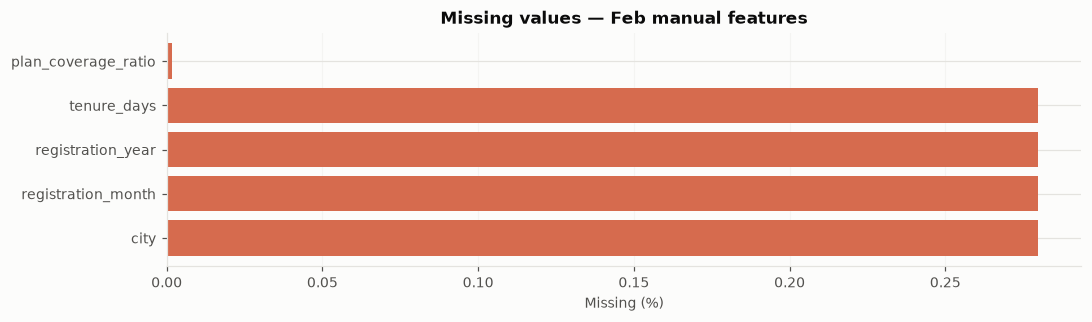

In [5]:
if len(missing_pct):
    fig, ax = plt.subplots(figsize=(10, max(3, len(missing_pct) * 0.4)))
    ax.barh(missing_pct.index, missing_pct.values, color='#d66b4e')
    ax.set_xlabel('Missing (%)')
    ax.set_title('Missing values — Feb manual features', fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('No missing values in the 48 features.')

## 4. Target variable

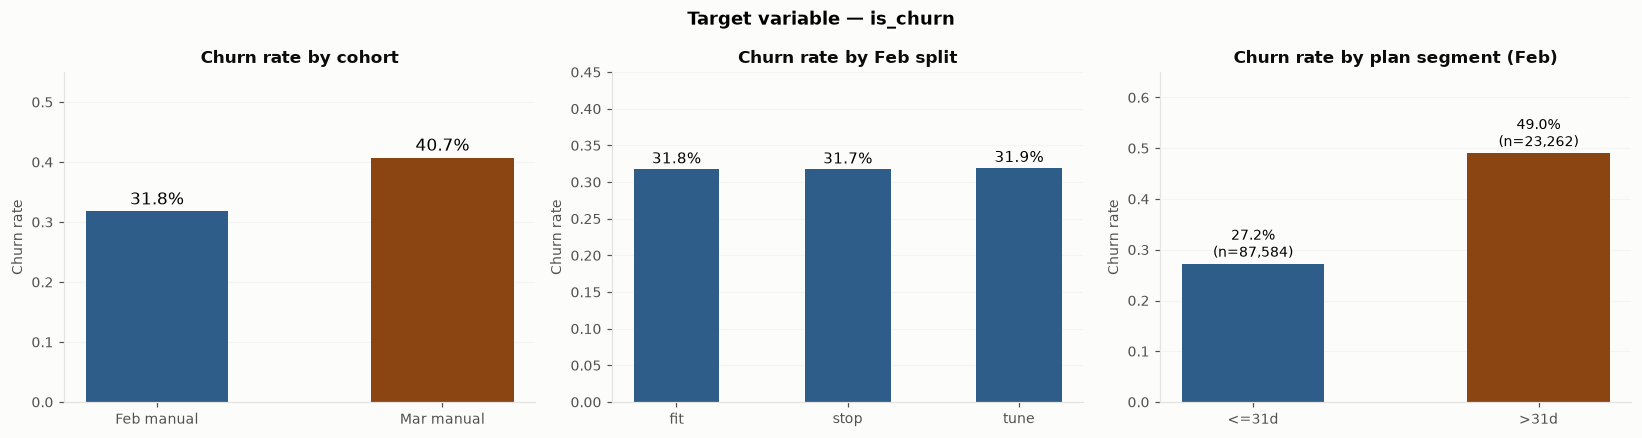

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cohorts = ['Feb manual', 'Mar manual']
rates   = [feb_m['is_churn'].mean(), mar_m['is_churn'].mean()]
bars = axes[0].bar(cohorts, rates, color=['#2f5d8a', '#8b4513'], width=0.5)
for b, v in zip(bars, rates):
    axes[0].text(b.get_x() + b.get_width()/2, v + 0.005, f'{v:.1%}',
                 ha='center', va='bottom', fontsize=11)
axes[0].set_ylim(0, 0.55)
axes[0].set_ylabel('Churn rate')
axes[0].set_title('Churn rate by cohort', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

split_rates = feb_m.groupby('split')['is_churn'].mean().reindex(['fit', 'stop', 'tune'])
bars = axes[1].bar(split_rates.index, split_rates.values, color='#2f5d8a', width=0.5)
for b, v in zip(bars, split_rates.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.003, f'{v:.1%}',
                 ha='center', va='bottom', fontsize=10)
axes[1].set_ylim(0, 0.45)
axes[1].set_ylabel('Churn rate')
axes[1].set_title('Churn rate by Feb split', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

seg_data = feb_m.groupby('plan_seg')['is_churn'].agg(['mean', 'count']).reset_index()
bars = axes[2].bar(seg_data['plan_seg'], seg_data['mean'],
                   color=['#2f5d8a', '#8b4513'], width=0.5)
for b, row in zip(bars, seg_data.itertuples()):
    axes[2].text(b.get_x() + b.get_width()/2, row.mean + 0.005,
                 f'{row.mean:.1%}\n(n={row.count:,})',
                 ha='center', va='bottom', fontsize=9)
axes[2].set_ylim(0, 0.65)
axes[2].set_ylabel('Churn rate')
axes[2].set_title('Churn rate by plan segment (Feb)', fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Target variable — is_churn', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Categorical features

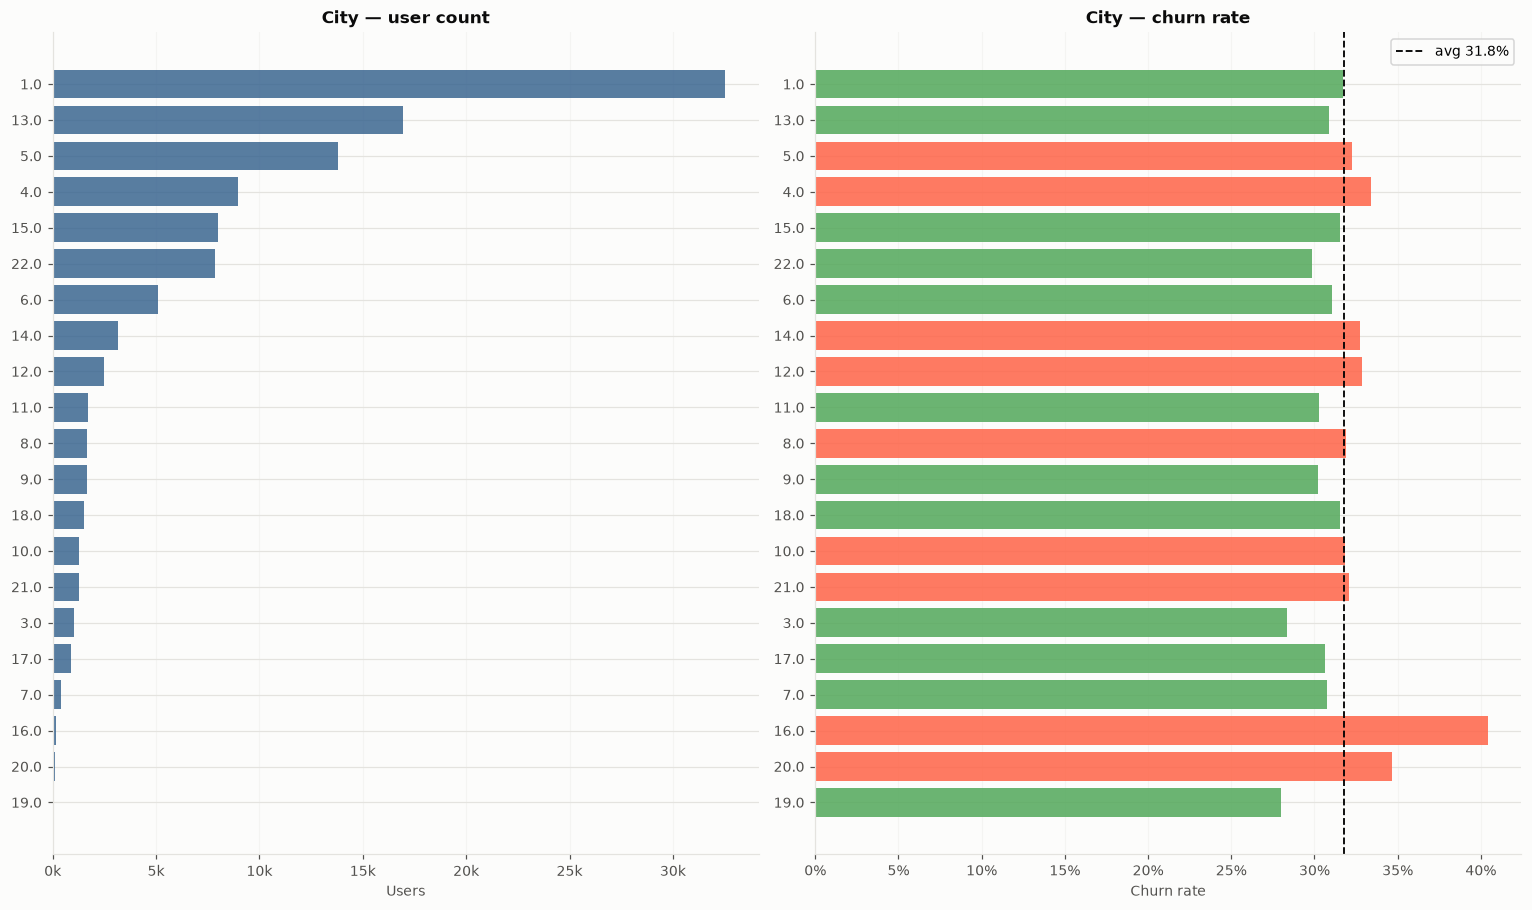

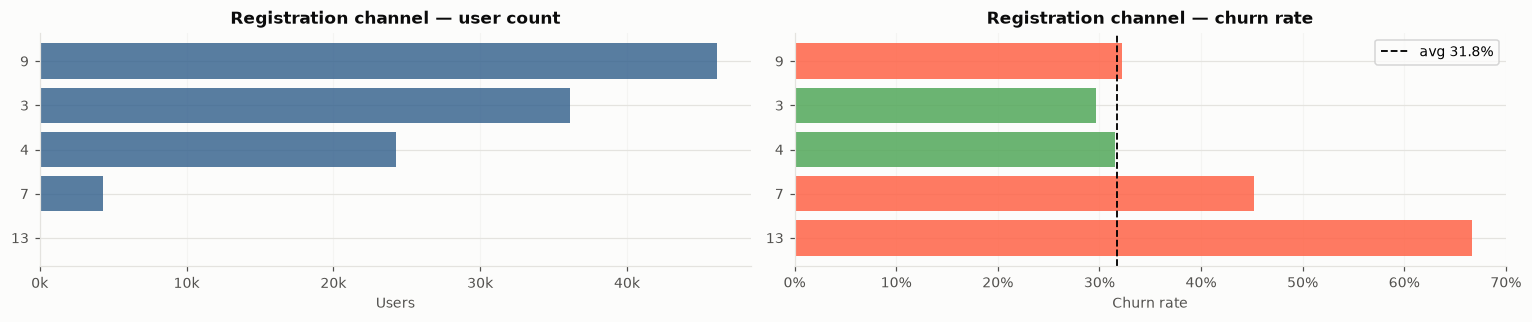

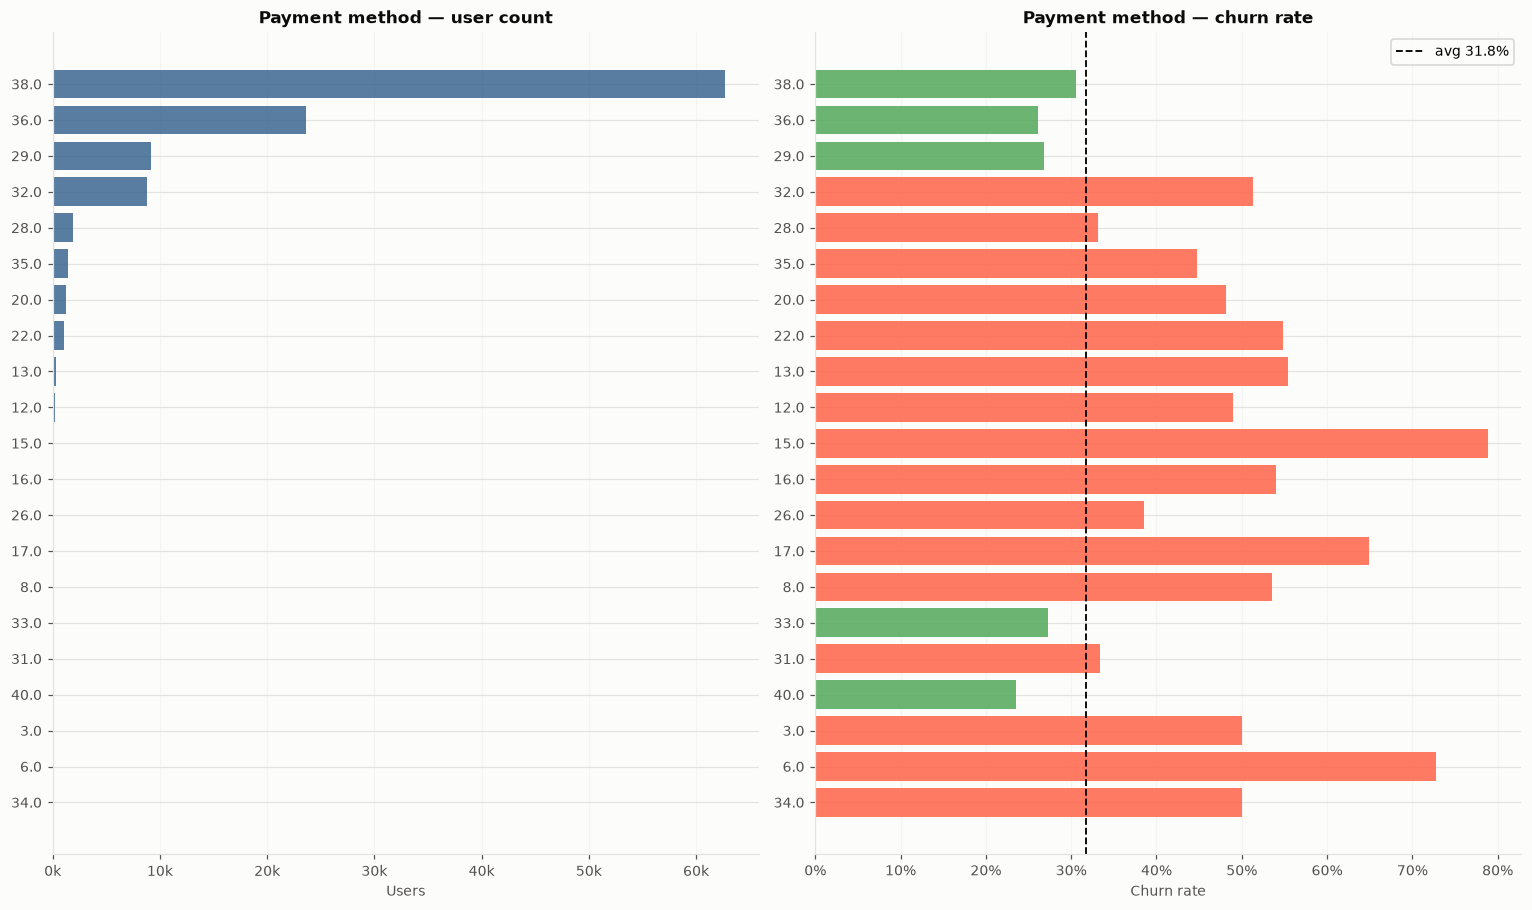

In [7]:
overall_rate = feb_m['is_churn'].mean()
CAT_LABELS   = {'city': 'City', 'registered_via': 'Registration channel',
                'last_payment_method_id': 'Payment method'}

for feat in CAT:
    grp = (feb_m.groupby(feat)['is_churn']
           .agg(['count', 'mean'])
           .rename(columns={'count': 'n', 'mean': 'churn_rate'})
           .sort_values('n', ascending=False))

    fig, axes = plt.subplots(1, 2, figsize=(14, max(3, len(grp) * 0.35 + 1)))

    axes[0].barh(grp.index.astype(str)[::-1], grp['n'].values[::-1], color='#2f5d8a', alpha=0.8)
    axes[0].set_xlabel('Users')
    axes[0].set_title(f'{CAT_LABELS[feat]} — user count', fontweight='bold')
    axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
    axes[0].grid(axis='x', alpha=0.3)

    colors = ['tomato' if v > overall_rate else '#52a85a' for v in grp['churn_rate'].values[::-1]]
    axes[1].barh(grp.index.astype(str)[::-1], grp['churn_rate'].values[::-1], color=colors, alpha=0.85)
    axes[1].axvline(overall_rate, color='black', lw=1.2, ls='--', label=f'avg {overall_rate:.1%}')
    axes[1].set_xlabel('Churn rate')
    axes[1].set_title(f'{CAT_LABELS[feat]} — churn rate', fontweight='bold')
    axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0%}'))
    axes[1].legend(fontsize=9)
    axes[1].grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

## 6. Numerical features — boxplots by churn label

Each panel shows side-by-side boxplots for **no-churn** (blue) vs **churn** (red)
on the February manual cohort.  Values are clipped at the 1st–99th percentile to
suppress outlier scale distortion.  Binary (0/1) features show churn-rate bars instead.

**How to read:** a large vertical separation between the two boxes means the feature
discriminates well between churners and non-churners.

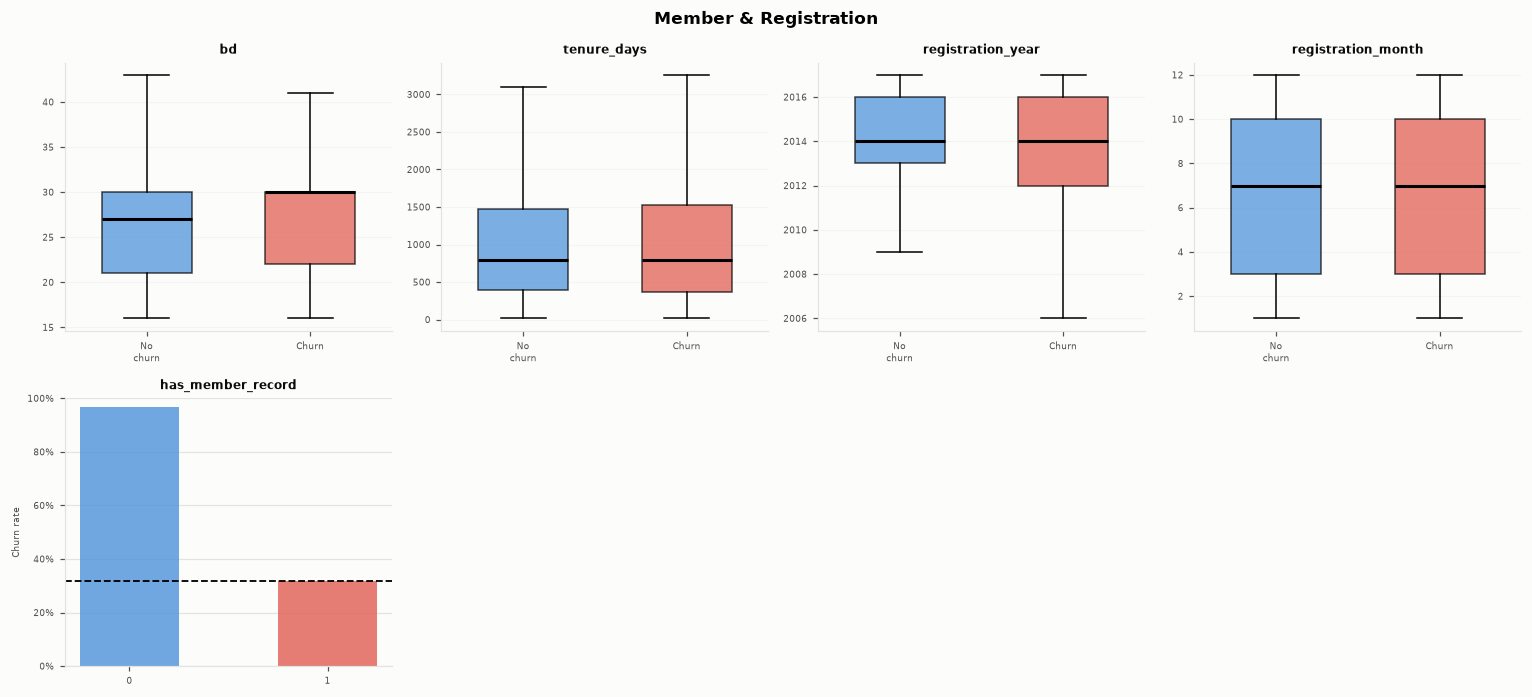

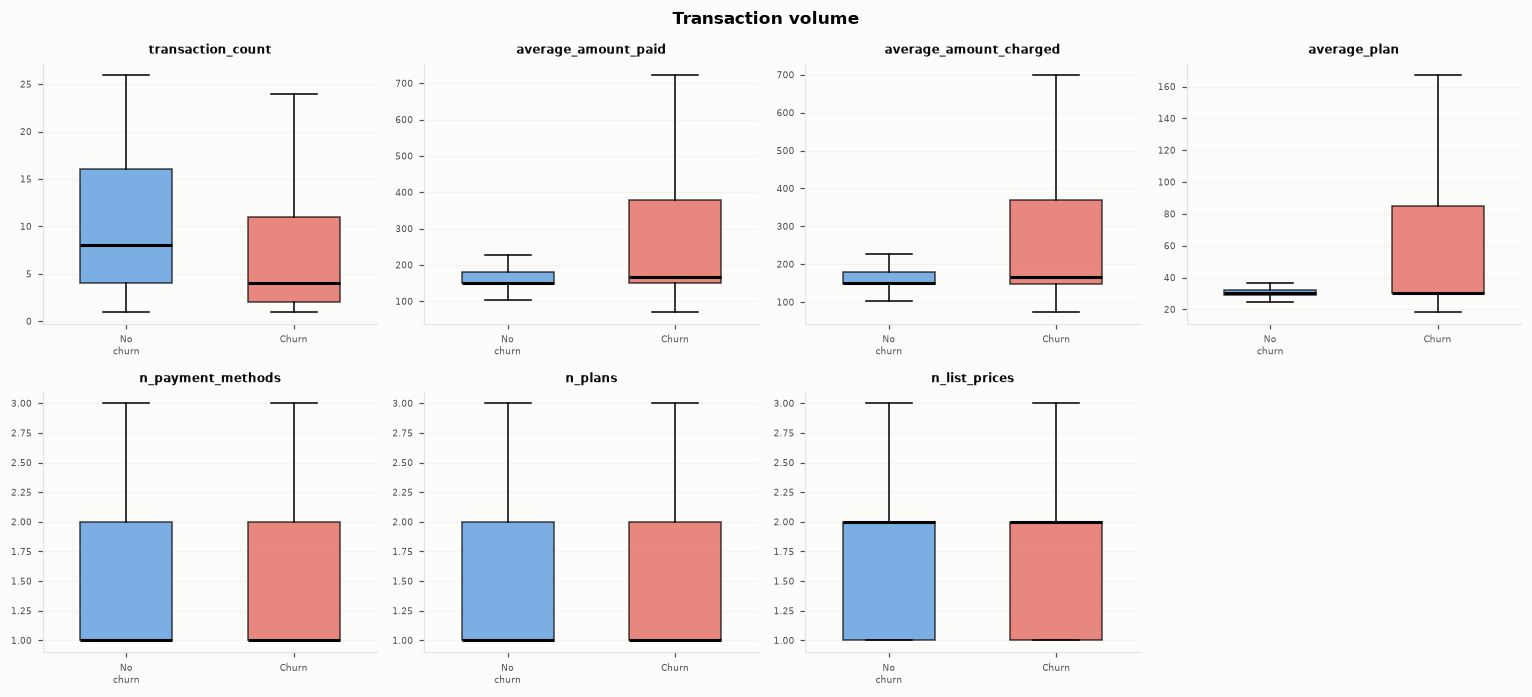

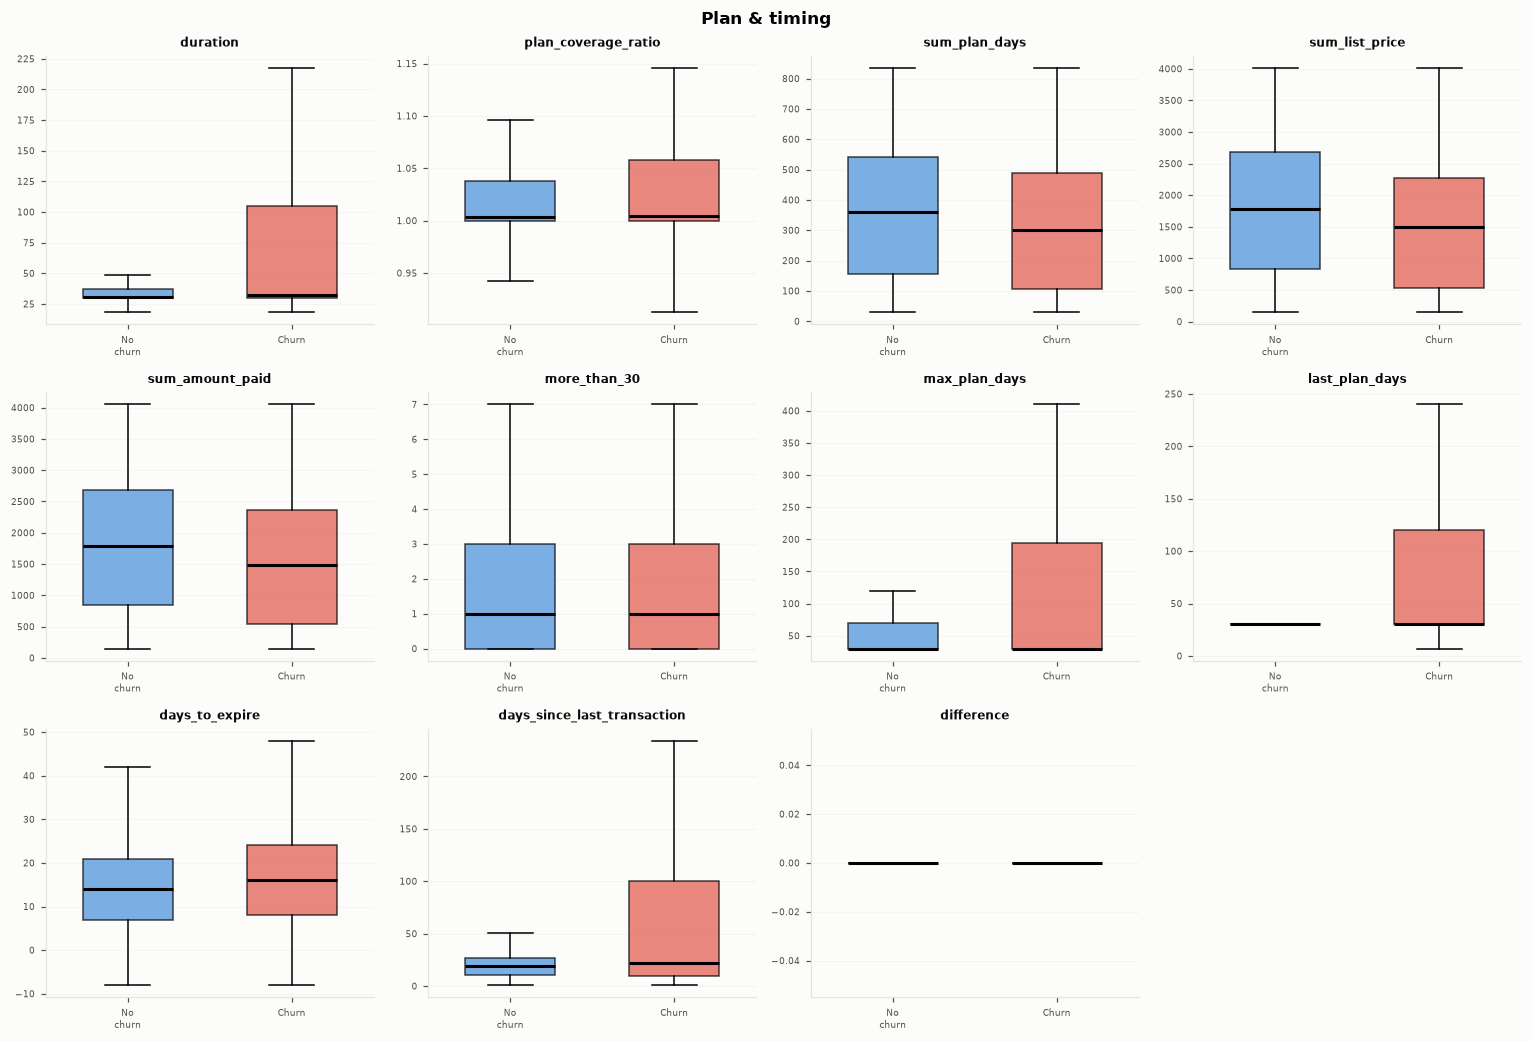

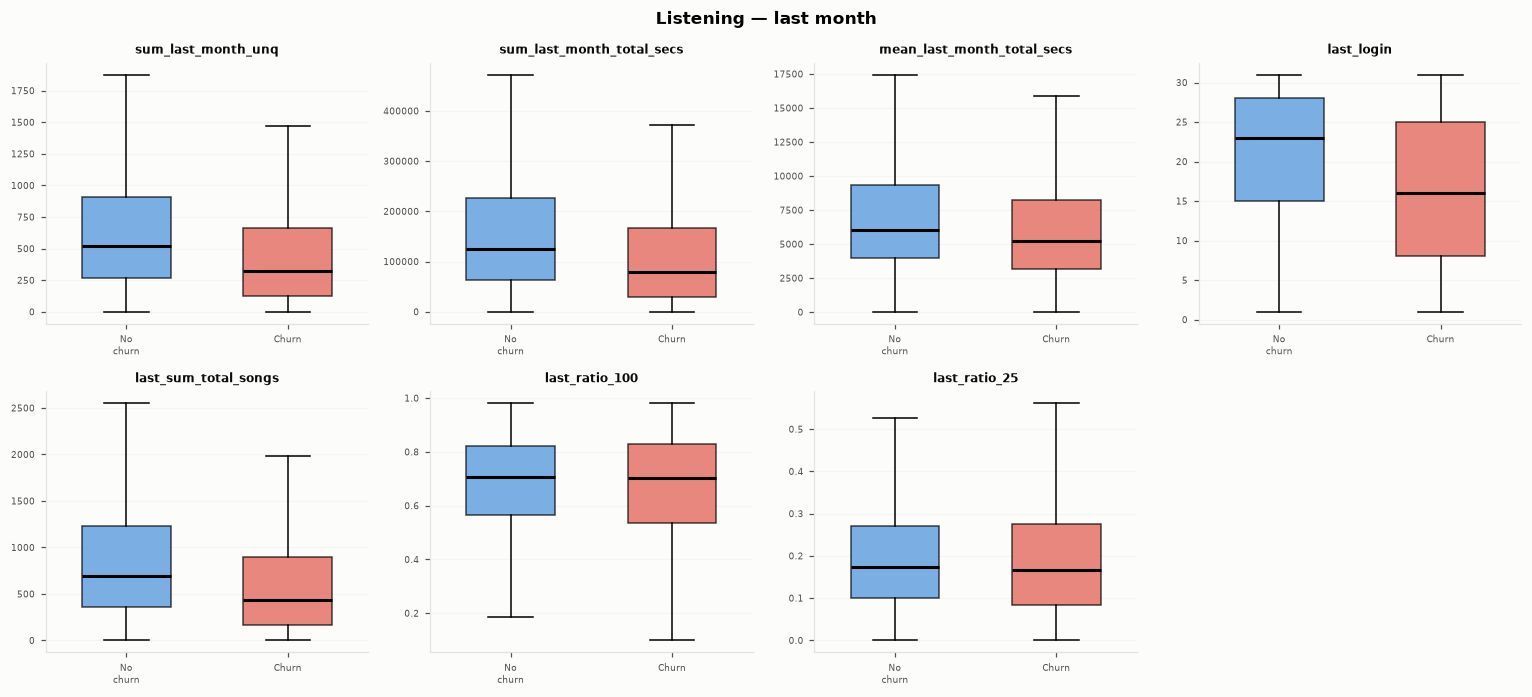

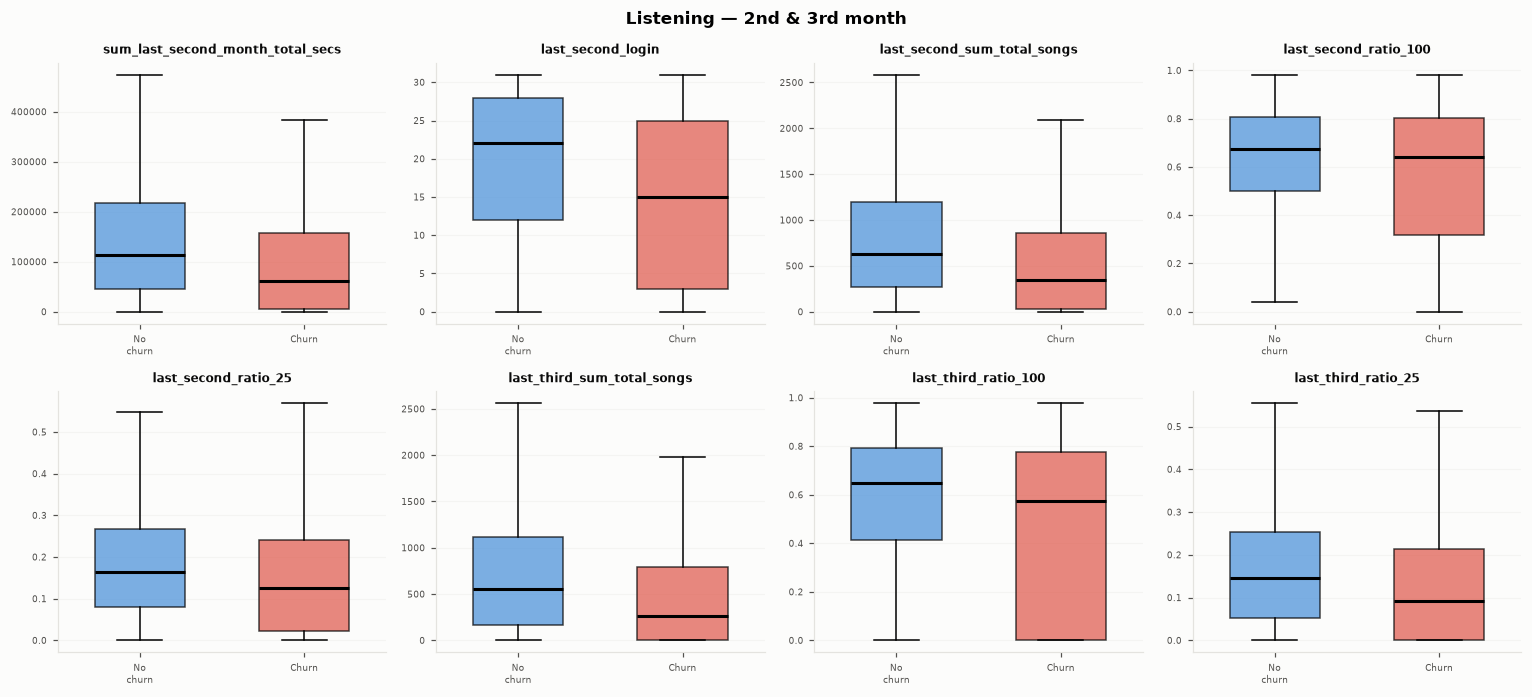

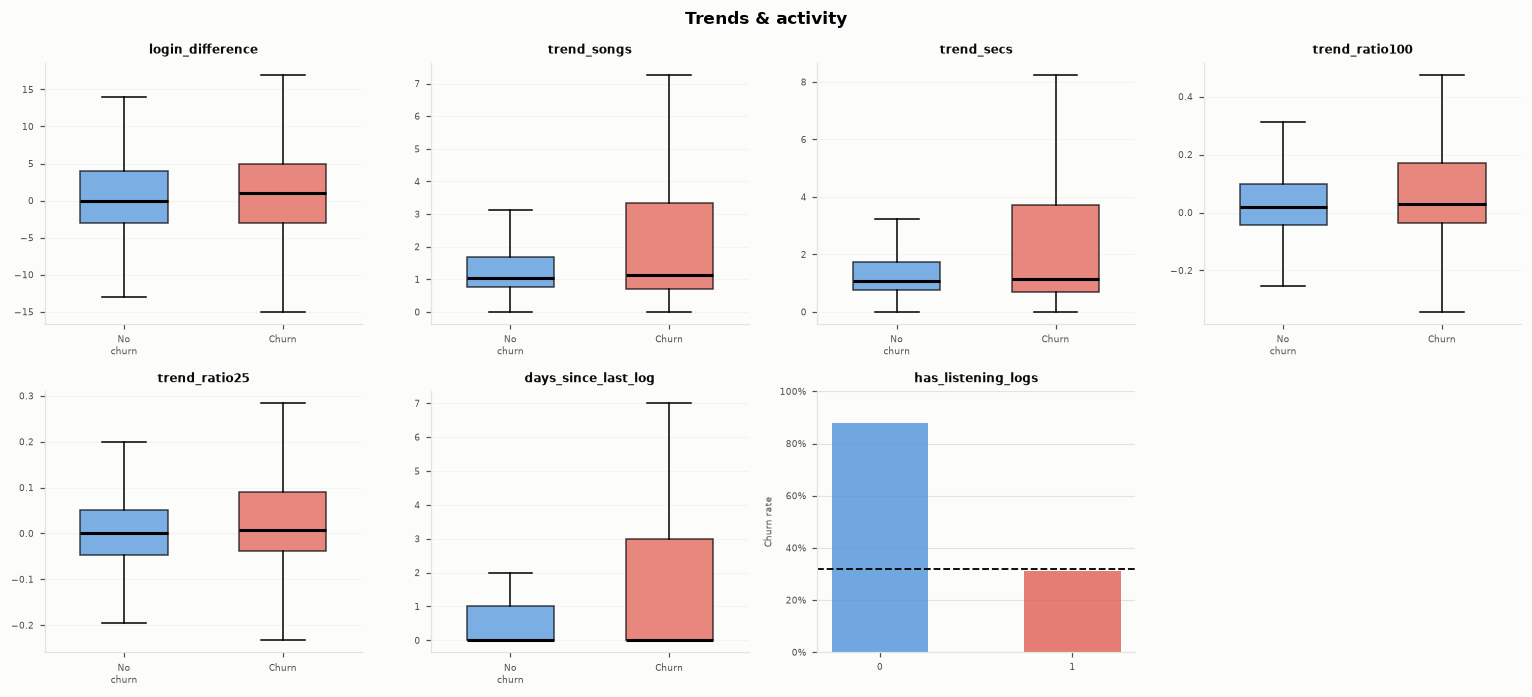

In [8]:
def _is_binary(s):
    return s.dropna().nunique() <= 2


def plot_boxplots_churn(title, features, df, n_cols=4):
    overall = df['is_churn'].mean()
    churn0  = df[df['is_churn'] == 0]
    churn1  = df[df['is_churn'] == 1]

    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols * 3.5, n_rows * 3.2))
    axes = np.array(axes).flatten()

    for i, feat in enumerate(features):
        ax = axes[i]
        s  = df[feat]

        if _is_binary(s):
            # Binary feature: churn rate per value (0 / 1)
            vals  = sorted(s.dropna().unique())
            rates = [df[df[feat] == v]['is_churn'].mean() for v in vals]
            clrs  = ['#4a90d9', '#e05a4e'] if len(vals) == 2 else ['#4a90d9'] * len(vals)
            ax.bar([str(int(v)) for v in vals], rates, color=clrs, alpha=0.78, width=0.5)
            ax.axhline(overall, color='black', lw=1.2, ls='--')
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
            ax.set_ylabel('Churn rate', fontsize=6)
            ax.set_ylim(0, min(1.0, max(rates) * 1.35 + 0.05))
        else:
            lo  = s.quantile(0.01)
            hi  = s.quantile(0.99)
            v0c = churn0[feat].dropna().clip(lo, hi).values
            v1c = churn1[feat].dropna().clip(lo, hi).values

            bp = ax.boxplot(
                [v0c, v1c],
                patch_artist=True,
                medianprops=dict(color='black', lw=2),
                showfliers=False,
                widths=0.55,
            )
            ax.set_xticklabels(['No\nchurn', 'Churn'])
            bp['boxes'][0].set_facecolor('#4a90d9')
            bp['boxes'][0].set_alpha(0.72)
            bp['boxes'][1].set_facecolor('#e05a4e')
            bp['boxes'][1].set_alpha(0.72)
            ax.grid(axis='y', alpha=0.3)

        ax.set_title(feat, fontsize=8, fontweight='bold')
        ax.tick_params(labelsize=6)

    for j in range(len(features), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()


for group_name, feats in GROUPS.items():
    plot_boxplots_churn(group_name, feats, feb_m, n_cols=4)

## 7. Spearman correlation with churn

Spearman ρ between each numerical feature and `is_churn` on the February manual cohort.
Positive = higher value → more churn.  Negative = higher value → less churn.

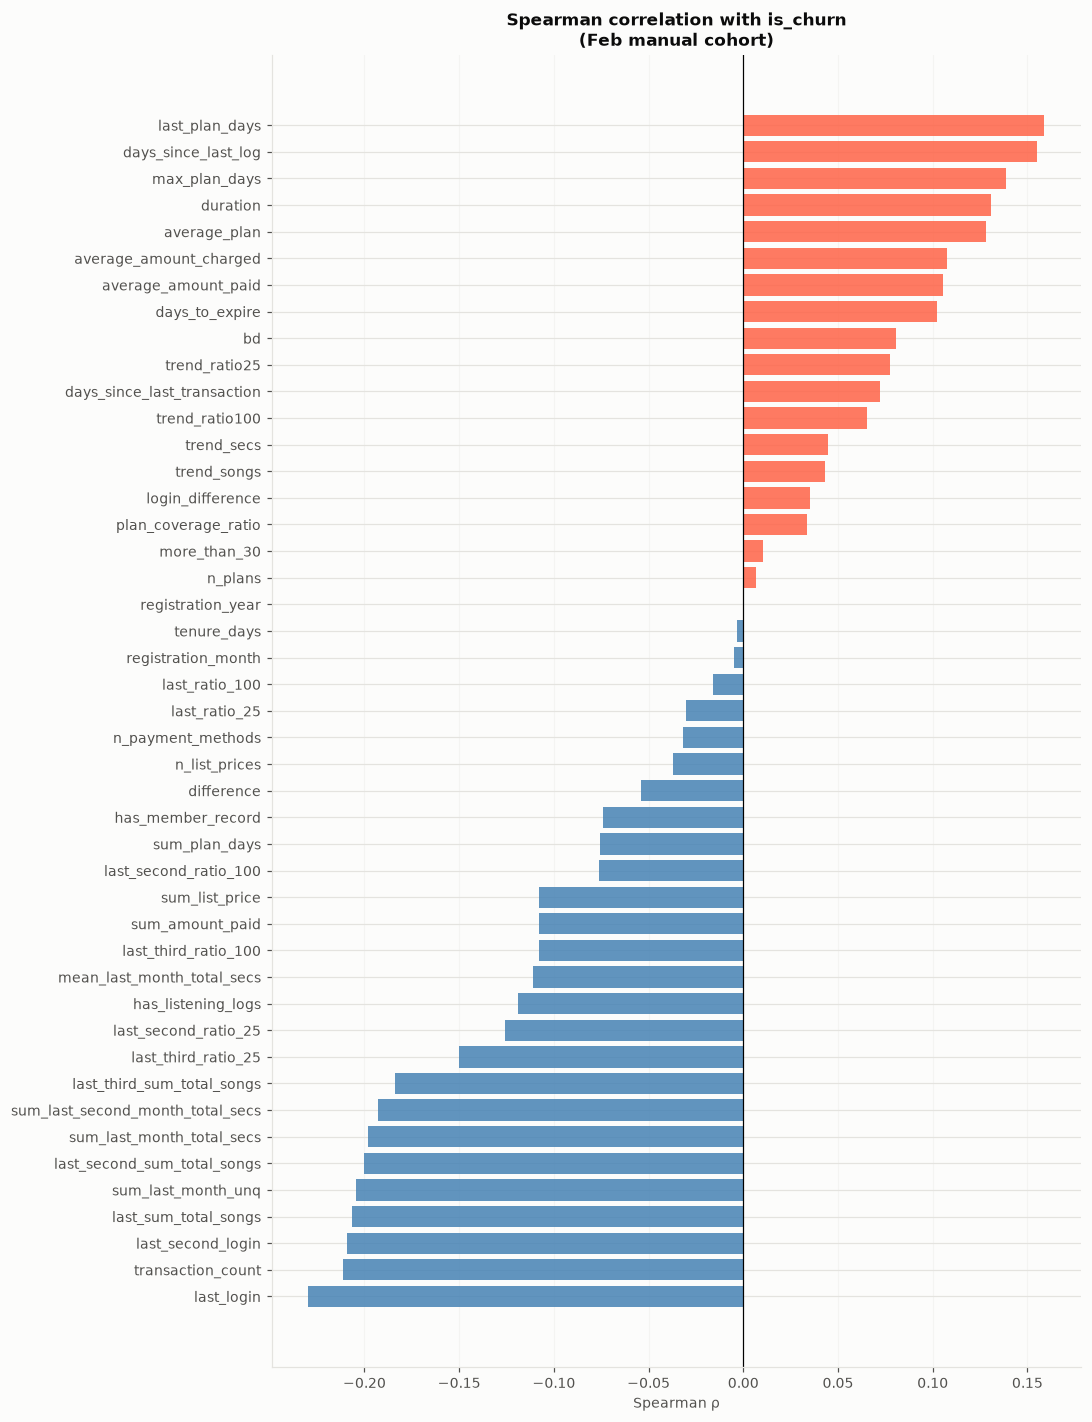

Top 10 positive:
last_plan_days            0.159
days_since_last_log       0.155
max_plan_days             0.139
duration                  0.131
average_plan              0.128
average_amount_charged    0.108
average_amount_paid       0.105
days_to_expire            0.102
bd                        0.081
trend_ratio25             0.078

Top 10 negative:
last_login                         -0.230
transaction_count                  -0.211
last_second_login                  -0.209
last_sum_total_songs               -0.207
sum_last_month_unq                 -0.205
last_second_sum_total_songs        -0.200
sum_last_month_total_secs          -0.198
sum_last_second_month_total_secs   -0.193
last_third_sum_total_songs         -0.184
last_third_ratio_25                -0.150


In [9]:
corr_vals = {}
for feat in NUM:
    mask = feb_m[feat].notna()
    r, _ = spearmanr(feb_m.loc[mask, feat], feb_m.loc[mask, 'is_churn'])
    corr_vals[feat] = r

corr_s = pd.Series(corr_vals).sort_values()

fig, ax = plt.subplots(figsize=(10, 13))
colors  = ['tomato' if v > 0 else 'steelblue' for v in corr_s.values]
ax.barh(corr_s.index, corr_s.values, color=colors, alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Spearman ρ')
ax.set_title('Spearman correlation with is_churn\n(Feb manual cohort)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('Top 10 positive:')
print(corr_s.tail(10).iloc[::-1].round(3).to_string())
print('\nTop 10 negative:')
print(corr_s.head(10).round(3).to_string())

## 8. XGBoost feature importance

From the trained `XGB_reweight` model saved in `artifacts/sherlock_w1_manual_reweighting`.
OHE-expanded categorical columns are summed back to the original feature name.

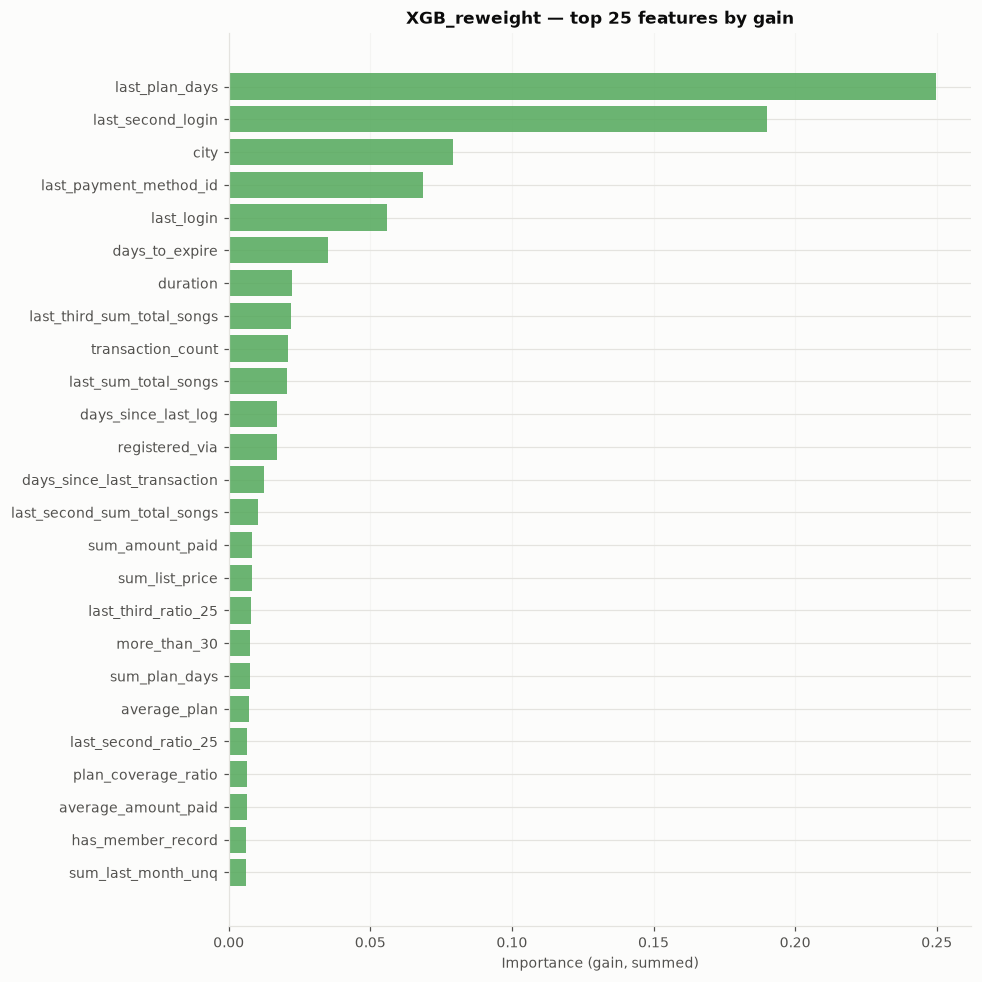

feature
last_plan_days                 0.2497
last_second_login              0.1902
city                           0.0794
last_payment_method_id         0.0685
last_login                     0.0560
days_to_expire                 0.0352
duration                       0.0225
last_third_sum_total_songs     0.0219
transaction_count              0.0210
last_sum_total_songs           0.0207
days_since_last_log            0.0172
registered_via                 0.0171
days_since_last_transaction    0.0124
last_second_sum_total_songs    0.0102
sum_amount_paid                0.0084
sum_list_price                 0.0081
last_third_ratio_25            0.0078
more_than_30                   0.0075
sum_plan_days                  0.0075
average_plan                   0.0073
last_second_ratio_25           0.0065
plan_coverage_ratio            0.0064
average_amount_paid            0.0064
has_member_record              0.0062
sum_last_month_unq             0.0060


In [10]:
artifact   = joblib.load(ARTIFACTS_DIR / 'models' / 'XGB_reweight.joblib')
prep_m     = artifact['preprocessor']
model      = artifact['model']

feat_names = prep_m.get_feature_names_out()
importance = model.feature_importances_


def agg_name(f):
    if '__' not in f:
        return f
    prefix, rest = f.split('__', 1)
    if prefix == 'cat':
        for cf in CAT:
            if rest.startswith(cf + '_') or rest == cf:
                return cf
        return rest
    return rest


imp_df    = pd.DataFrame({'raw': feat_names, 'imp': importance})
imp_df['feature'] = imp_df['raw'].apply(agg_name)
feat_imp  = imp_df.groupby('feature')['imp'].sum().sort_values(ascending=False)

TOP = 25
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(feat_imp.index[:TOP][::-1], feat_imp.values[:TOP][::-1], color='#52a85a', alpha=0.85)
ax.set_xlabel('Importance (gain, summed)')
ax.set_title(f'XGB_reweight — top {TOP} features by gain', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print(feat_imp.head(25).round(4).to_string())

## 9. Feature drift — February → March

Standardised mean shift `(μ_Mar − μ_Feb) / σ_Feb` for each numerical feature.
Large absolute values indicate distribution drift between training and test cohorts.
Red = increased in March · Blue = decreased in March.

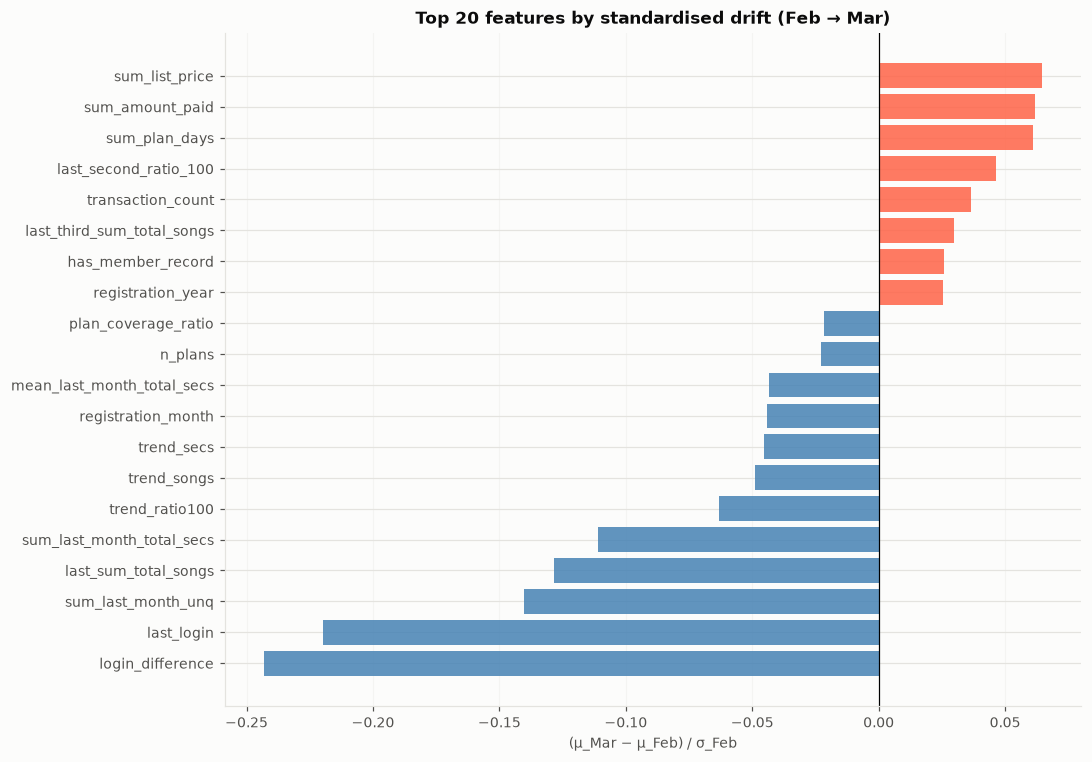

                      feat    mean_feb    mean_mar  std_shift
          login_difference      1.4472     -0.3622     -0.243
                last_login     19.4049     17.4494     -0.220
        sum_last_month_unq    624.8827    540.2040     -0.140
      last_sum_total_songs    859.8245    745.9699     -0.128
 sum_last_month_total_secs 163317.6986 142783.6531     -0.111
            sum_list_price   1698.3378   1769.7342      0.065
            trend_ratio100      0.0797      0.0644     -0.063
           sum_amount_paid   1722.6429   1792.6011      0.062
             sum_plan_days    351.6575    365.8923      0.061
               trend_songs     60.4908     46.7393     -0.049
     last_second_ratio_100      0.5927      0.6059      0.046
                trend_secs  10355.9189   7927.8486     -0.045
        registration_month      6.6861      6.5255     -0.044
mean_last_month_total_secs   7453.4658   7171.7925     -0.043
         transaction_count      9.1435      9.4199      0.036
last_thi

In [11]:
feb_means = feb_m[NUM].mean()
mar_means = mar_m[NUM].mean()
feb_stds  = feb_m[NUM].std().clip(lower=1e-6)

drift_abs  = ((mar_means - feb_means) / feb_stds).abs().sort_values(ascending=False)
drift_dir  = (mar_means - feb_means) / feb_stds

TOP_D      = 20
top_feats  = drift_abs.head(TOP_D).index.tolist()
drift_vals = drift_dir[top_feats].sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['tomato' if v > 0 else 'steelblue' for v in drift_vals.values]
ax.barh(drift_vals.index, drift_vals.values, color=colors, alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('(μ_Mar − μ_Feb) / σ_Feb')
ax.set_title('Top 20 features by standardised drift (Feb → Mar)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

drift_tbl = pd.DataFrame({
    'feat':      top_feats,
    'mean_feb':  feb_means[top_feats].round(4).values,
    'mean_mar':  mar_means[top_feats].round(4).values,
    'std_shift': drift_dir[top_feats].round(3).values,
}).sort_values('std_shift', key=abs, ascending=False).reset_index(drop=True)
print(drift_tbl.to_string(index=False))

cohort                   feature        mean   median         std  pct_missing
   Feb          login_difference      1.4472      0.0      7.4390          0.0
   Mar          login_difference     -0.3622     -2.0      7.3996          0.0
   Feb                last_login     19.4049     21.0      8.9052          0.0
   Mar                last_login     17.4494     19.0      8.1661          0.0
   Feb        sum_last_month_unq    624.8827    457.0    602.9863          0.0
   Mar        sum_last_month_unq    540.2040    384.0    551.9203          0.0
   Feb      last_sum_total_songs    859.8245    615.0    887.9951          0.0
   Mar      last_sum_total_songs    745.9699    516.0    827.6180          0.0
   Feb sum_last_month_total_secs 163317.6986 111427.5 184932.1190          0.0
   Mar sum_last_month_total_secs 142783.6531  92581.5 176806.9346          0.0


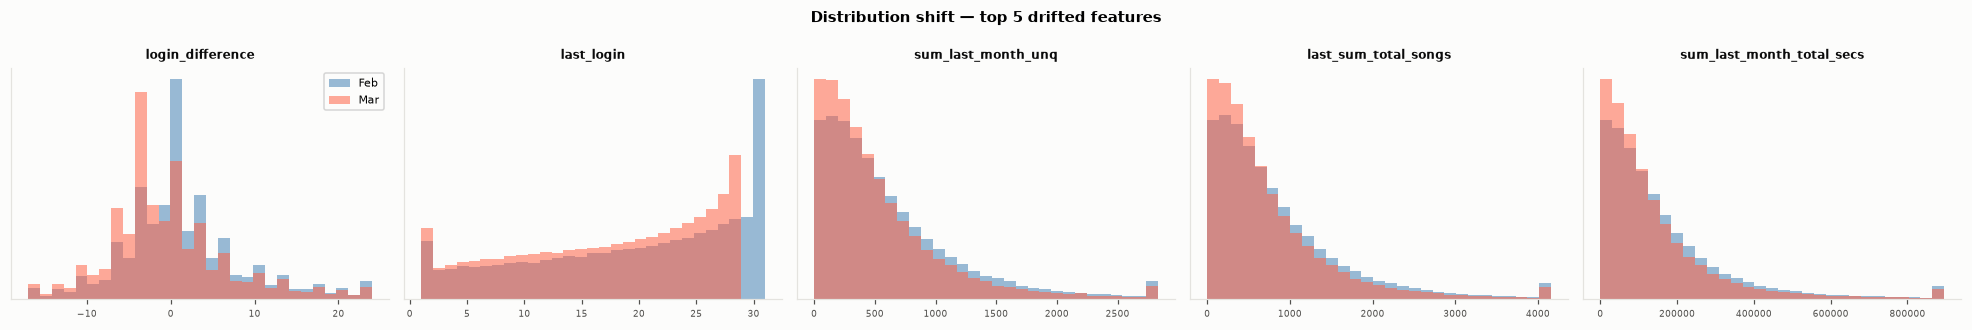

In [12]:
# Detailed stats + distribution shift for top 5 drifted features
top5 = drift_abs.head(5).index.tolist()

rows = []
for feat in top5:
    for cohort_name, df_ in [('Feb', feb_m), ('Mar', mar_m)]:
        rows.append({'cohort': cohort_name, 'feature': feat,
                     'mean': round(df_[feat].mean(), 4),
                     'median': round(df_[feat].median(), 4),
                     'std': round(df_[feat].std(), 4),
                     'pct_missing': round(df_[feat].isnull().mean() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, feat in zip(axes, top5):
    lo   = min(feb_m[feat].quantile(0.01), mar_m[feat].quantile(0.01))
    hi   = max(feb_m[feat].quantile(0.99), mar_m[feat].quantile(0.99))
    bins = np.linspace(lo, hi, 30)
    ax.hist(feb_m[feat].clip(lo, hi), bins=bins, density=True,
            alpha=0.55, color='steelblue', label='Feb')
    ax.hist(mar_m[feat].clip(lo, hi), bins=bins, density=True,
            alpha=0.55, color='tomato', label='Mar')
    ax.set_title(feat, fontsize=8, fontweight='bold')
    ax.set_yticks([])
    ax.tick_params(labelsize=6)
    if feat == top5[0]:
        ax.legend(fontsize=7)
fig.suptitle('Distribution shift — top 5 drifted features', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()